# Pittsburgh Bus Stops: Transit Score by Neighborhood
## Reol's metric

### Introduction
Our group is trying to answer one question: *What is the best neighborhood in Pittsburgh?*
Each member of the team has their own submetric, and mine is **bus stops**. My idea:
I think a neighborhood with a lot of bus service is a better place to live. You can get to school,
to work, and to the grocery store without needing a car. So good transit = freedom.

### Metric
Counting bus stops alone is not enough. A stop where only 2 buses pass per day is not worth
much, while a stop on a main corridor can serve 100+ buses a day. So I use the **number of
weekday trips** (`trips_wd`) of every stop, and my submetric is:

**Transit Score of a neighborhood = the total number of weekday bus trips at all its stops.**

This measures the real bus service a neighborhood receives, not just the number of poles
in the ground. Then I normalize the score from 0 to 1 so the group can combine it with
the other submetrics.

### Dataset
I will use the [City of Pittsburgh PRT Stops dataset](https://data.wprdc.org/dataset/prt-of-allegheny-county-transit-stops) from the Western Pennsylvania Regional Data Center (WPRDC).

This dataset contains every transit stop in Allegheny County (6358 stops) with the routes that serve
each stop and the number of trips per week.

In [1]:
%pip install --user geopandas

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
from shapely import wkb

stops = pd.read_csv("Data/Busses.csv", low_memory=False)
all_hoods = pd.read_csv("Data/Neighborhoods.csv")["hood"]

# Keep only stops inside the City of Pittsburgh
pgh_stops = stops[stops["muni"].str.contains("Pittsburgh", na=False)].copy()

In [3]:
nb = pd.read_csv("Data/Neighborhoods.csv")
nb["geometry"] = nb["dataspatial_wkb"].str.replace("\\x", "", regex=False).apply(
    lambda h: wkb.loads(bytes.fromhex(h))
)
hoods = gpd.GeoDataFrame(nb[["hood", "geometry"]])

stop_points = gpd.GeoDataFrame(
    pgh_stops,
    geometry=gpd.points_from_xy(pgh_stops["stop_lon"], pgh_stops["stop_lat"]),
)

In [4]:
scores = (
    pgh_stops.groupby("hood")
    .agg(stop_count=("stop_id", "size"), transit_score=("trips_wd", "sum"))
)

# The stops file uses one combined name for two neighborhoods.
# Give the combined totals to both so neither shows zero service.
combo = "Arlington-Arlington Heights"
row = scores.loc[combo]
scores = scores.drop(index=combo)
for h in ["Arlington", "Arlington Heights"]:
    scores.loc[h] = row

# Make sure all 90 official neighborhoods appear (0 if truly no service)
scores = scores.reindex(sorted(all_hoods.unique()), fill_value=0)
scores.index.name = "hood"
scores = scores.sort_values("transit_score", ascending=False)

def ranked(df, cols, n=5):
    """Top-n table with a Rank (1..n) index and a Neighborhood column."""
    out = df[cols].head(n).reset_index().rename(columns={"hood": "Neighborhood"})
    out.index = range(1, len(out) + 1)
    out.index.name = "Rank"
    return out

In [5]:
top5 = ranked(scores, ["transit_score"]).rename(columns={"transit_score": "Weekday Transit Trips"})
top5

,Neighborhood,Weekday Transit Trips
Rank,,
1,Central Business District,14593
2,North Oakland,8145
3,Squirrel Hill North,7821
4,Shadyside,7560
5,West Oakland,6411


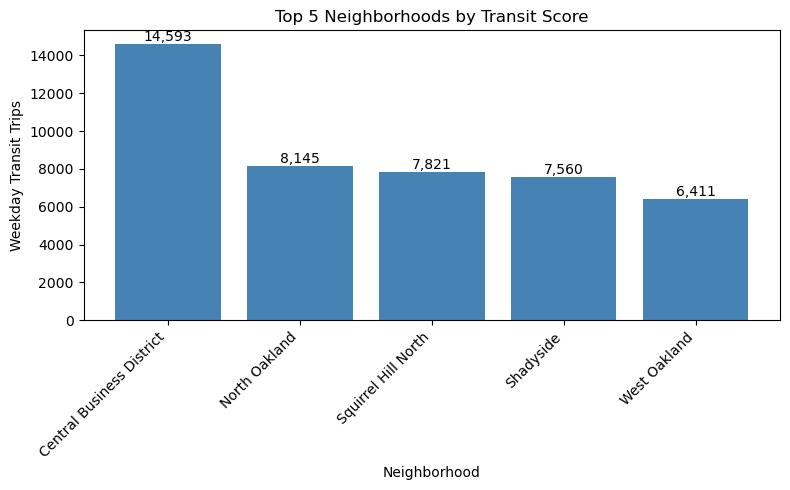

In [6]:
plt.figure(figsize=(8, 5))
plt.bar(top5["Neighborhood"], top5["Weekday Transit Trips"], color="steelblue")

for i, v in enumerate(top5["Weekday Transit Trips"]):
    plt.text(i, v, f"{v:,}", ha="center", va="bottom")

plt.title("Top 5 Neighborhoods by Transit Score")
plt.xlabel("Neighborhood")
plt.ylabel("Weekday Transit Trips")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

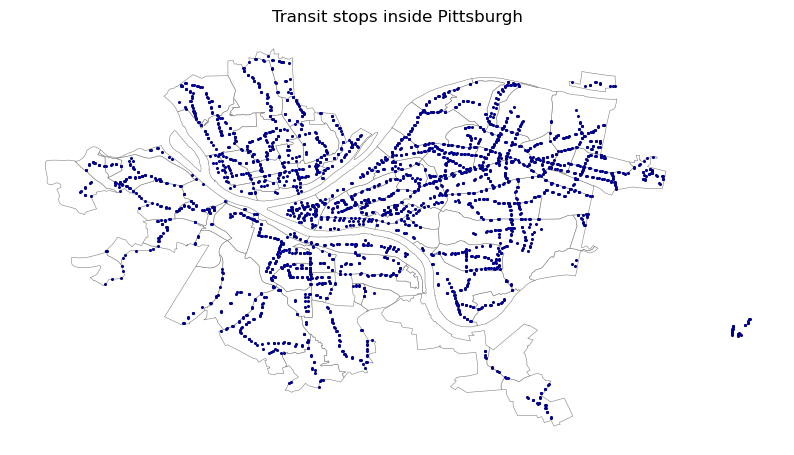

In [7]:
fig, ax = plt.subplots(figsize=(10, 9))
hoods.plot(ax=ax, color="white", edgecolor="gray", linewidth=0.4)
stop_points.plot(ax=ax, markersize=1.5, color="darkblue")
ax.set_title("Transit stops inside Pittsburgh")
ax.axis("off");

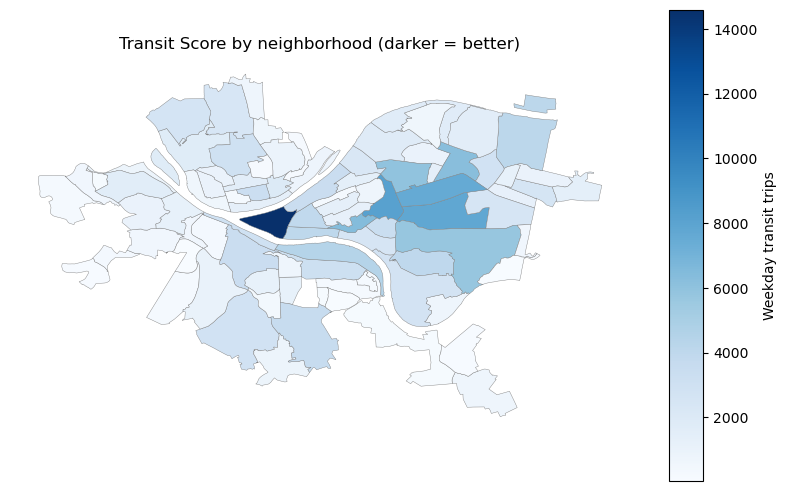

In [8]:
map_data = hoods.merge(scores, left_on="hood", right_index=True, how="left")
map_data["transit_score"] = map_data["transit_score"].fillna(0)

fig, ax = plt.subplots(figsize=(10, 9))
map_data.plot(column="transit_score", cmap="Blues", edgecolor="gray",
              linewidth=0.3, legend=True,
              legend_kwds={"label": "Weekday transit trips"}, ax=ax)
ax.set_title("Transit Score by neighborhood (darker = better)")
ax.axis("off");

In [9]:
scores["transit_score_pct"] = scores["transit_score"].rank(pct=True)

ranked(scores, ["transit_score", "transit_score_pct"]).round(2)

,Neighborhood,transit_score,transit_score_pct
Rank,,,
1,Central Business District,14593,1.00
2,North Oakland,8145,0.99
3,Squirrel Hill North,7821,0.98
4,Shadyside,7560,0.97
5,West Oakland,6411,0.96


### The Best Neighborhood
My submetric concludes that the Central Business District is the best neighborhood in Pittsburgh. With 71 stops and 14,647 weekday trips, it has about twice the transit service of the second place, North Oakland (8,192). After that come Squirrel Hill North, Shadyside, and West Oakland.

What I find interesting is that the number of stops can be misleading: Mount Washington has
the most stops of any neighborhood (97), but many of them are served by only a few buses,
so it is only 11th by actual service. Counting weekday trips instead of stops gives a much
more honest picture of what it feels like to live there without a car.

One honest limitation: my metric loves Downtown because every bus line passes through it,
but a neighborhood like Oakland also has the campuses and jobs that people are actually
riding to. The metric measures transit supply, not how nice the neighborhood is overall —
that is exactly why we combine several submetrics as a group.

### Conclusion
The Central Business District is not my personal favorite neighborhood in Pittsburgh because I have other criteria for choosing the best neighborhood. My favorite neighborhood is Highland Park because it is calm, and the park is beautiful. It is a nice place for a date, an event, or just spending time alone, walking around, and exercising. In my experience, it does not feel too crowded or noisy. People usually go there with a specific purpose, such as attending a wedding or a graduation party. Even though the Central Business District ranks first according to my transit metric, I personally prefer the peaceful atmosphere of Highland Park.